In [23]:
import os
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

In [24]:
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

In [25]:
csv_file = "data/all_sources_isc_vgg_embeddings.csv"
df = pd.read_csv(csv_file)
df.head()

,source,label,Value,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
0,mtt,C,94.774444,0.011359,0.241203,0.344854,0.0,11.211005,0.004637,0.0,...,0.188881,0.0,0.954637,2.482550,0.000000,0.118003,0.000000,0.000000,1.703285,0.000000
1,mtt,C,94.774444,0.025853,0.000000,1.069848,0.0,11.320415,0.000000,0.0,...,0.000000,0.0,0.168406,6.162180,0.000000,0.107752,0.000000,0.271620,4.474264,0.000000
2,mtt,C,94.774444,0.480963,0.000000,3.107252,0.0,4.831994,0.064862,0.0,...,0.124030,0.0,0.665731,1.306546,0.030879,0.144269,0.005907,0.232978,1.154307,0.000000
3,mtt,C,94.774444,0.000000,0.000000,0.058814,0.0,6.624664,0.000000,0.0,...,0.316281,0.0,0.318968,0.330109,0.480029,0.542135,0.000000,0.008872,3.581180,0.289227
4,mtt,C,94.774444,0.000000,0.000000,0.119758,0.0,8.961069,0.000000,0.0,...,0.099849,0.0,0.034700,1.626213,0.012560,0.605835,0.000000,0.025230,1.533522,0.180085


In [26]:
df.shape

(23845, 515)

In [27]:
meta_cols = ['source', 'label', 'Value']
feature_cols = [c for c in df.columns if c.startswith('vgg_')]

print(f"Metadata summary:\n{df[meta_cols].describe(include='all')}")

Metadata summary:
       source  label       Value
count   23845  23845  982.000000
unique      5      3         NaN
top      jimt      I         NaN
freq    21848  11978         NaN
mean      NaN    NaN   88.145686
std       NaN    NaN   61.962304
min       NaN    NaN    2.454000
25%       NaN    NaN   23.575000
50%       NaN    NaN   94.945000
75%       NaN    NaN  120.987500
max       NaN    NaN  271.664444


In [10]:
df[feature_cols].isna().sum()

vgg_0      0
vgg_1      0
vgg_2      0
vgg_3      0
vgg_4      0
          ..
vgg_507    0
vgg_508    0
vgg_509    0
vgg_510    0
vgg_511    0
Length: 512, dtype: int64

In [14]:
df['label'].value_counts()

label
I    11978
C    11591
S      276
Name: count, dtype: int64

In [16]:
ct = pd.crosstab(
    df['label'], 
    df['source'], 
    margins=True, 
    margins_name='Total',
    dropna=False  # Includes NaN values if present
)

print(ct)

source  alamar  chroma   jimt  mtt  study18  Total
label                                             
C          307       4  10464  235      581  11591
I          230       5  11384  136      223  11978
S           16       4      0   58      198    276
Total      553      13  21848  429     1002  23845


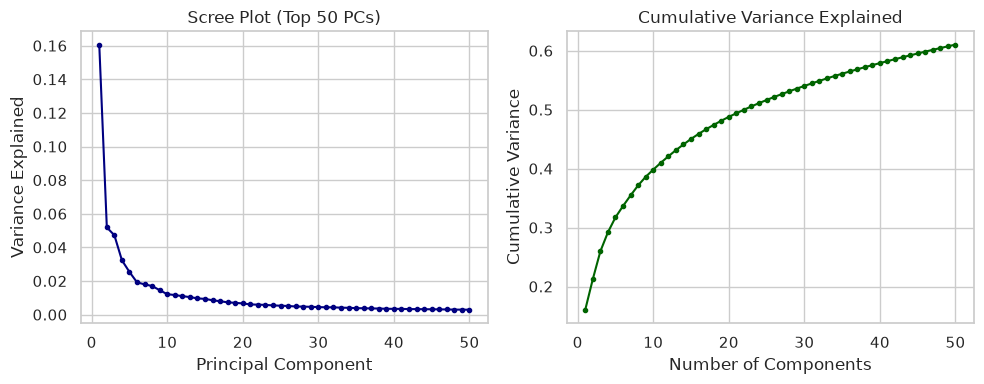

In [11]:
# PCA, diagnostics and batch effect analysis
X = df[feature_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_diag = PCA(n_components=50, random_state=SEED)
X_pca_diag = pca_diag.fit_transform(X_scaled)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, 51), pca_diag.explained_variance_ratio_, marker='.', color='navy')
plt.title('Scree Plot (Top 50 PCs)')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')

plt.subplot(1, 2, 2)
plt.plot(range(1, 51), np.cumsum(pca_diag.explained_variance_ratio_), marker='.', color='darkgreen')
plt.title('Cumulative Variance Explained')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')
plt.tight_layout()
plt.show()

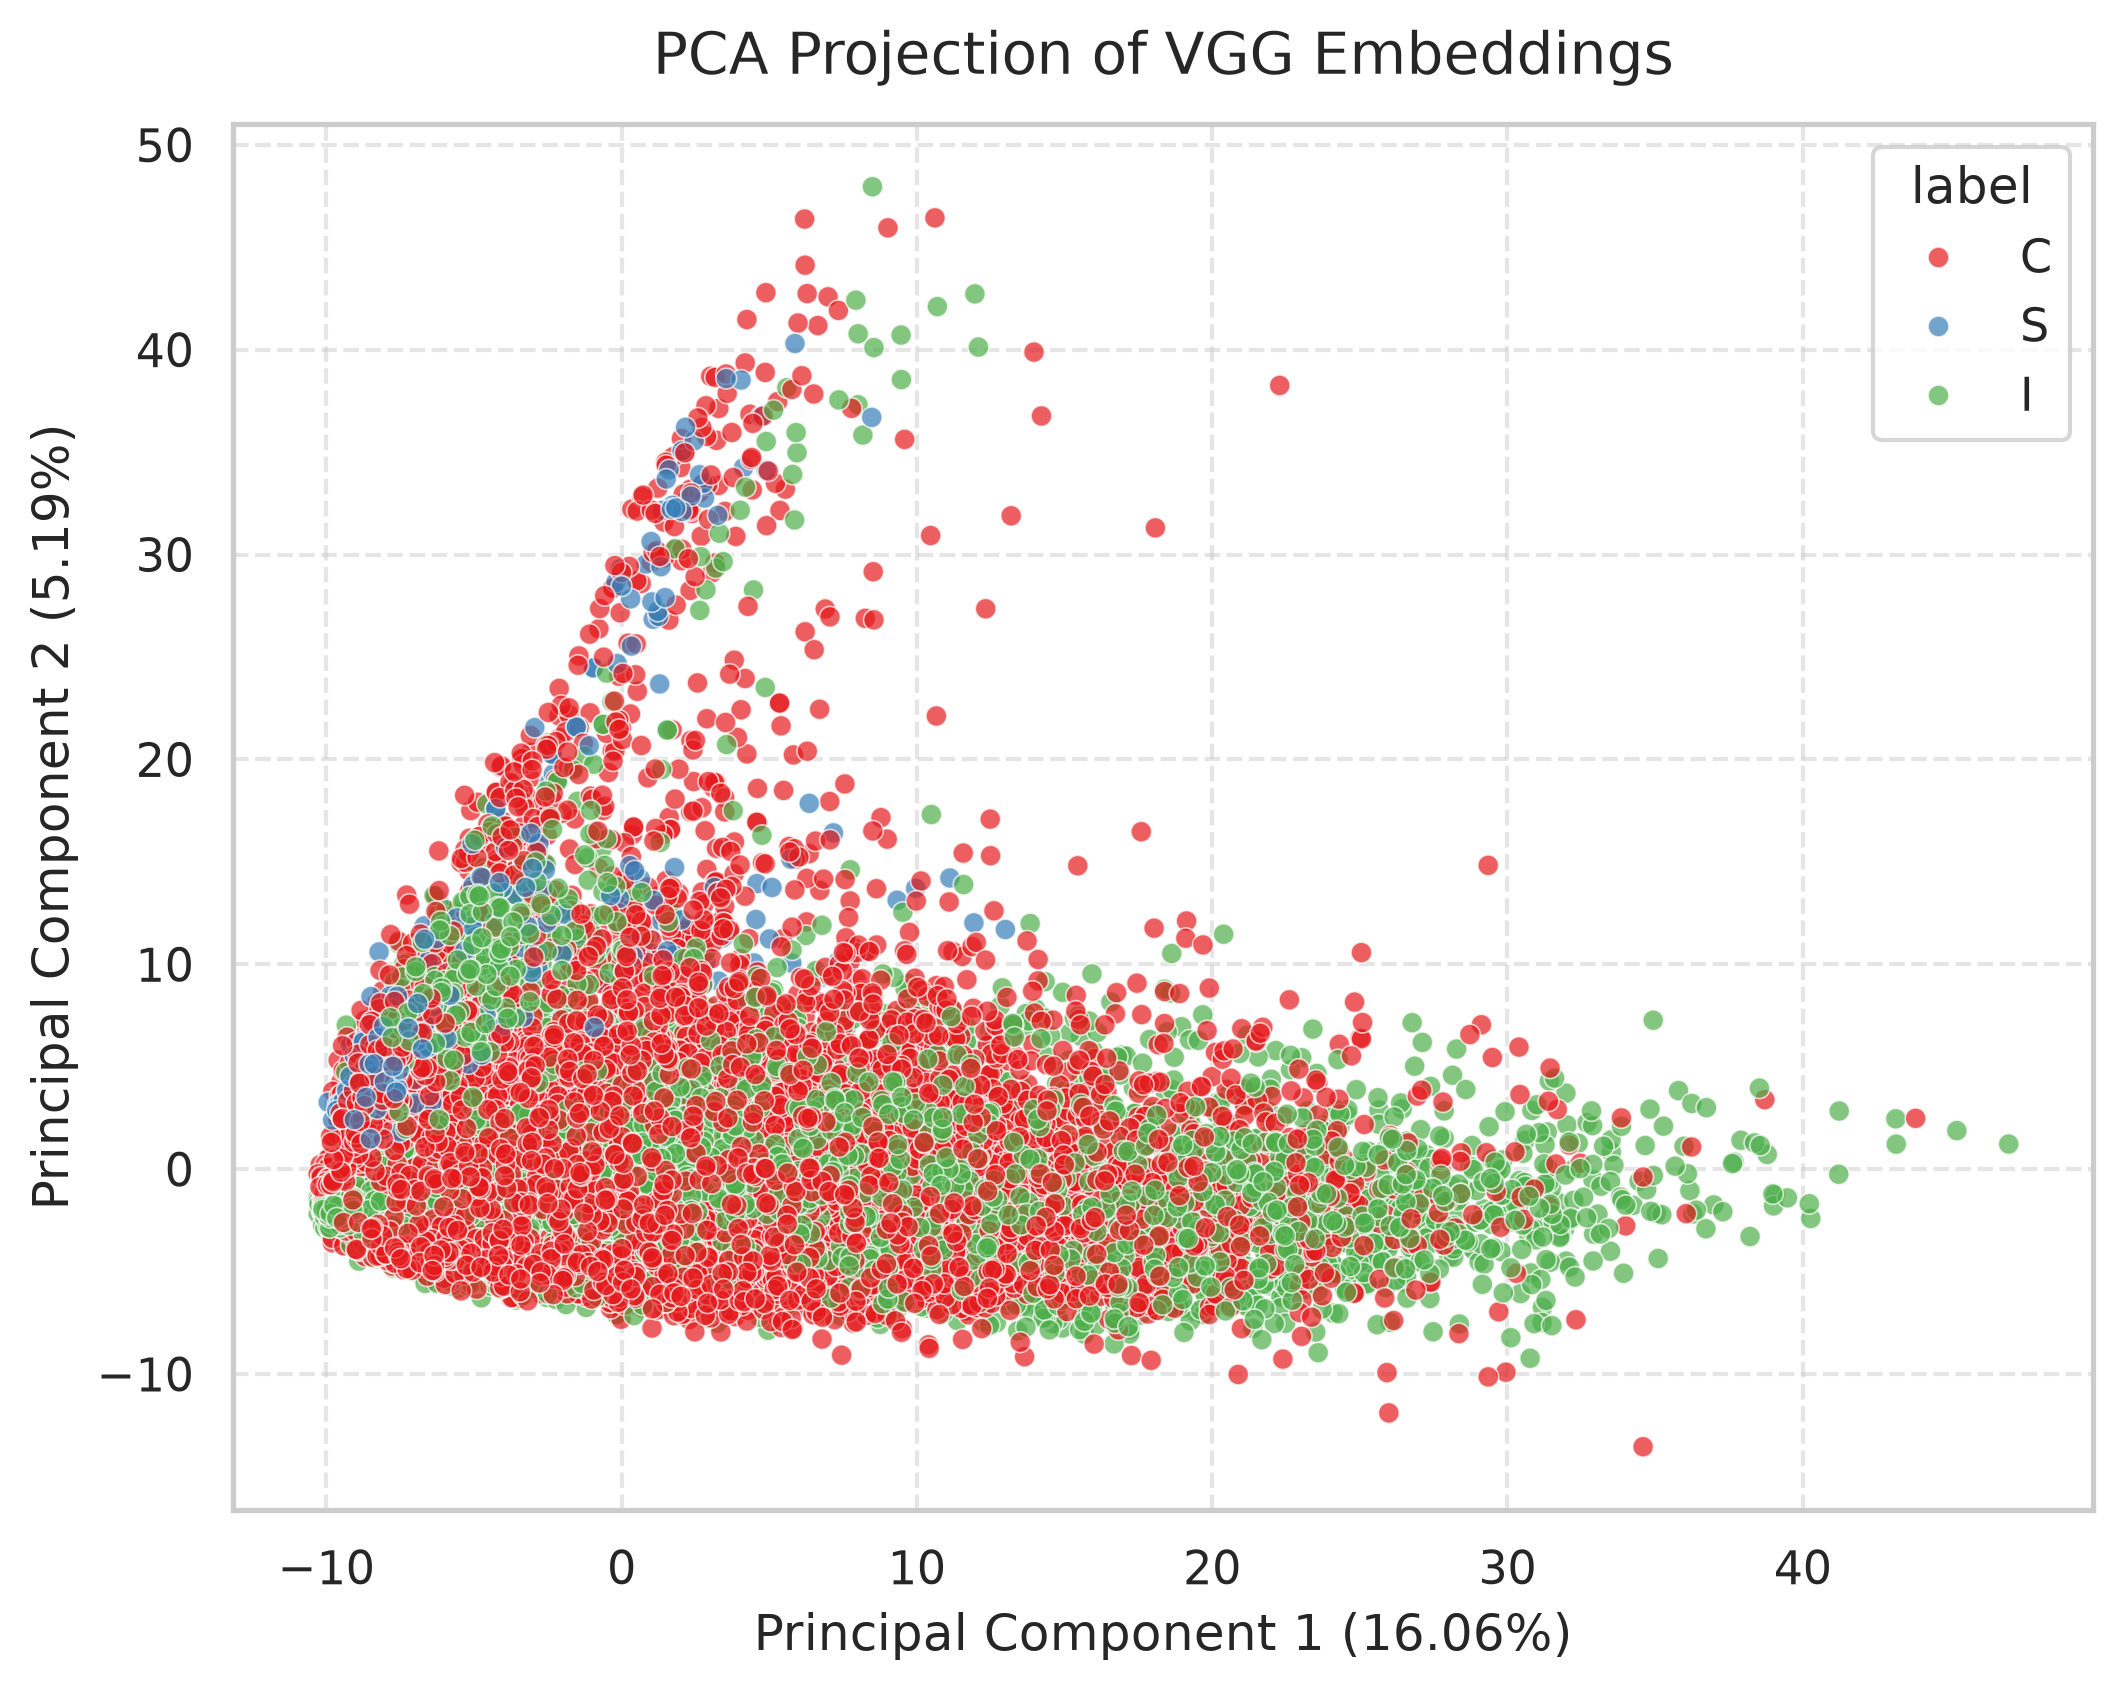

<Figure size 500x400 with 0 Axes>

In [13]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

var_exp = pca.explained_variance_ratio_ * 100

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['label'] = df['label'].values  # or df['source']

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='label',
    palette='Set1',
    alpha=0.7,
    s=25,
    ax=ax
)

ax.set_xlabel(f'Principal Component 1 ({var_exp[0]:.2f}%)', fontsize=12)
ax.set_ylabel(f'Principal Component 2 ({var_exp[1]:.2f}%)', fontsize=12)
ax.set_title('PCA Projection of VGG Embeddings', fontsize=14, pad=12)
ax.grid(True, linestyle='--', alpha=0.5)

plt.figure(figsize=(5, 4))
plt.tight_layout()
#plt.savefig('pca_plot.png', dpi=300, bbox_inches='tight')
plt.show()

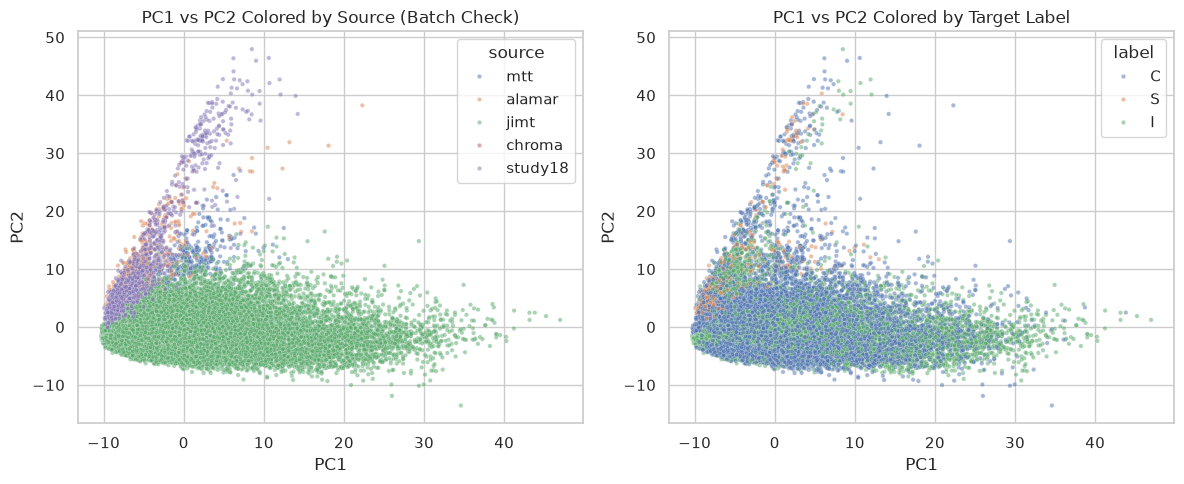

In [15]:
# correlation with source and label
df_pca = pd.DataFrame(X_pca_diag[:, :5], columns=[f'PC{i+1}' for i in range(5)])
df_pca = pd.concat([df[meta_cols].reset_index(drop=True), df_pca], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='source', alpha=0.5, s=10, ax=axes[0])
axes[0].set_title('PC1 vs PC2 Colored by Source (Batch Check)')

sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='label', alpha=0.5, s=10, ax=axes[1])
axes[1].set_title('PC1 vs PC2 Colored by Target Label')
plt.tight_layout()
plt.show()

Significant seperation by the source - severe batch effect. But the view may also be deteriorated by the 2D representation and heavy disbalance in lable-source distribution. I will try to visualize data within most prevalent class to access local/internal structure.

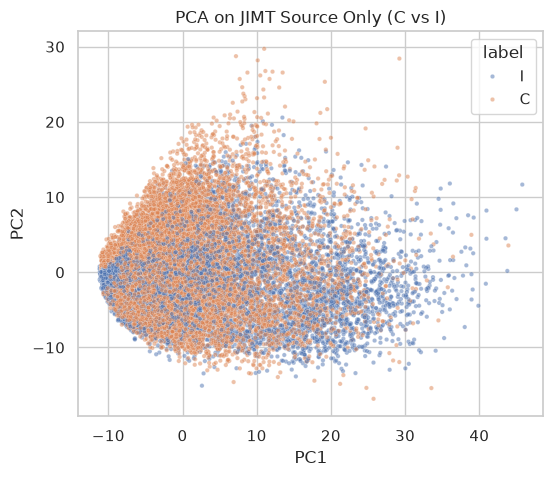

In [17]:
#filter for the largest source
df_jimt = df[df['source'] == 'jimt'].copy()
X_jimt = scaler.fit_transform(df_jimt[feature_cols].values)

pca_jimt = PCA(n_components=2).fit_transform(X_jimt)

plt.figure(figsize=(6, 5))
sns.scatterplot(x=pca_jimt[:, 0], y=pca_jimt[:, 1], hue=df_jimt['label'], alpha=0.5, s=10)
plt.title('PCA on JIMT Source Only (C vs I)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

/home/nikolaieva/ML/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


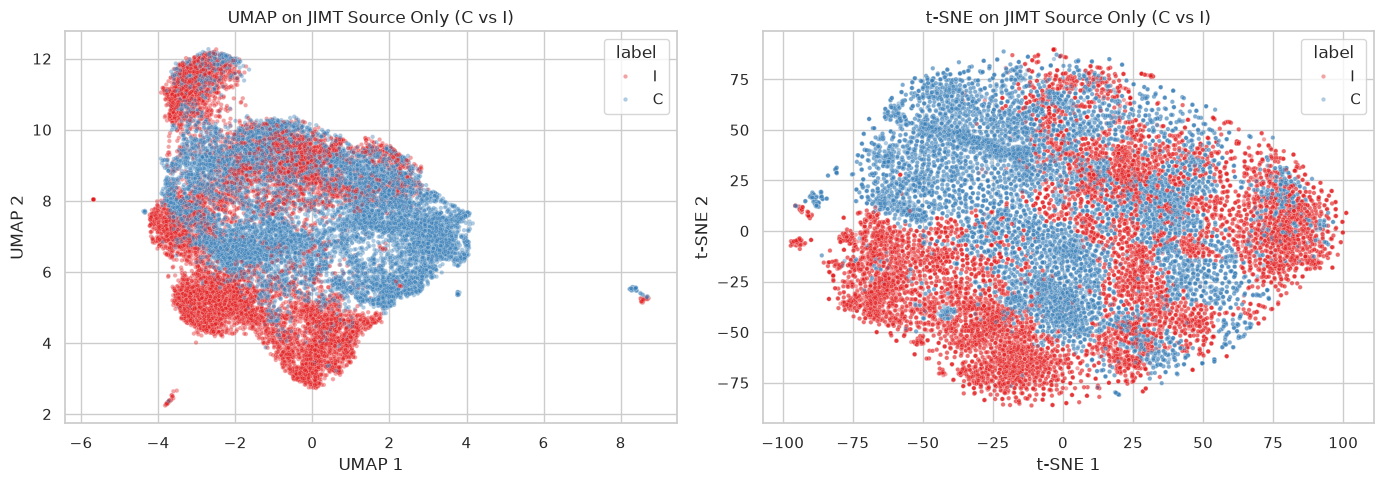

In [19]:
#UMAP and t-SNE on the largest source
reducer_jimt = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42)
X_jimt_umap = reducer_jimt.fit_transform(X_jimt)

# 2. Compute t-SNE
tsne_jimt = TSNE(n_components=2, perplexity=30, random_state=42)
X_jimt_tsne = tsne_jimt.fit_transform(X_jimt)

# 3. Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# UMAP Plot
sns.scatterplot(
    x=X_jimt_umap[:, 0], 
    y=X_jimt_umap[:, 1], 
    hue=df_jimt['label'], 
    alpha=0.4, 
    s=10, 
    palette='Set1',
    ax=axes[0]
)
axes[0].set_title('UMAP on JIMT Source Only (C vs I)')
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

# t-SNE Plot
sns.scatterplot(
    x=X_jimt_tsne[:, 0], 
    y=X_jimt_tsne[:, 1], 
    hue=df_jimt['label'], 
    alpha=0.4, 
    s=10, 
    palette='Set1',
    ax=axes[1]
)
axes[1].set_title('t-SNE on JIMT Source Only (C vs I)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')

plt.tight_layout()
plt.show()

The biological signal is lost even within single batch. So globally, the batch effect exists, and either PCA is inable of detecting biological signal due to the relationship non-linearity or this signal is absent at all.

/home/nikolaieva/ML/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


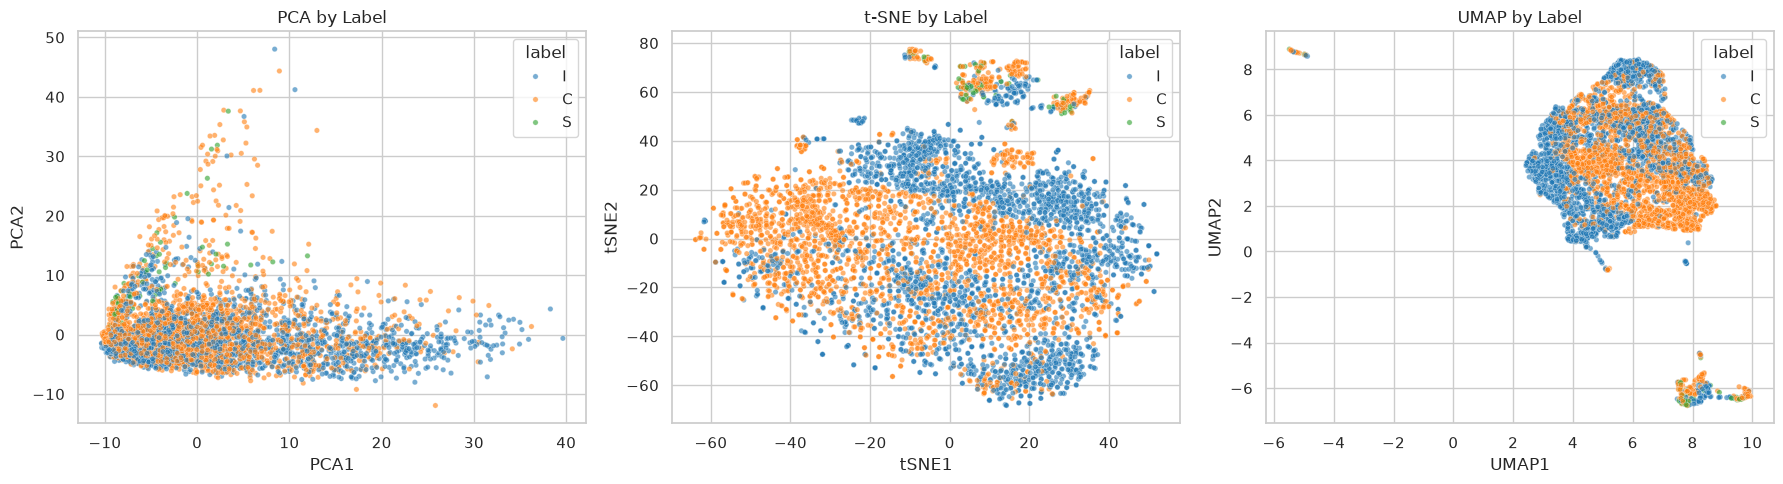

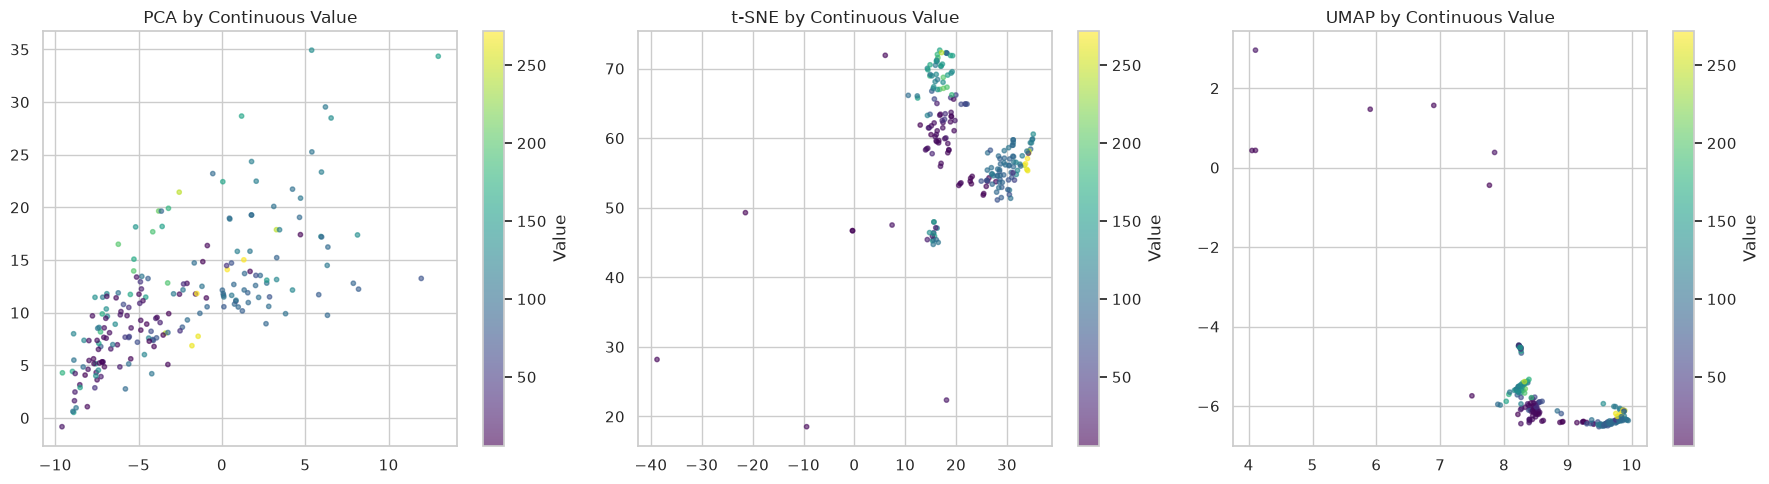

In [18]:
### embedding comparison

N_SUB = min(5000, len(df))
sub_idx = np.random.choice(len(df), N_SUB, replace=False)

df_sub = df.iloc[sub_idx].copy().reset_index(drop=True)
X_sub_scaled = X_scaled[sub_idx]

# Projections
pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_sub_scaled)
tsne_2d = TSNE(n_components=2, perplexity=30, random_state=SEED, n_jobs=-1).fit_transform(X_sub_scaled)
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(X_sub_scaled)

df_sub['PCA1'], df_sub['PCA2'] = pca_2d[:, 0], pca_2d[:, 1]
df_sub['tSNE1'], df_sub['tSNE2'] = tsne_2d[:, 0], tsne_2d[:, 1]
df_sub['UMAP1'], df_sub['UMAP2'] = umap_2d[:, 0], umap_2d[:, 1]

# Plotting Comparison across Labels
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, x_c, y_c) in zip(axes, [('PCA', 'PCA1', 'PCA2'), ('t-SNE', 'tSNE1', 'tSNE2'), ('UMAP', 'UMAP1', 'UMAP2')]):
    sns.scatterplot(data=df_sub, x=x_c, y=y_c, hue='label', alpha=0.6, s=15, ax=ax, palette='tab10')
    ax.set_title(f'{title} by Label')
plt.tight_layout()
plt.show()

# Plotting Comparison across Continuous 'Value'
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, x_c, y_c) in zip(axes, [('PCA', 'PCA1', 'PCA2'), ('t-SNE', 'tSNE1', 'tSNE2'), ('UMAP', 'UMAP1', 'UMAP2')]):
    sc = ax.scatter(df_sub[x_c], df_sub[y_c], c=df_sub['Value'], cmap='viridis', s=10, alpha=0.6)
    plt.colorbar(sc, ax=ax, label='Value')
    ax.set_title(f'{title} by Continuous Value')
plt.tight_layout()
plt.show()

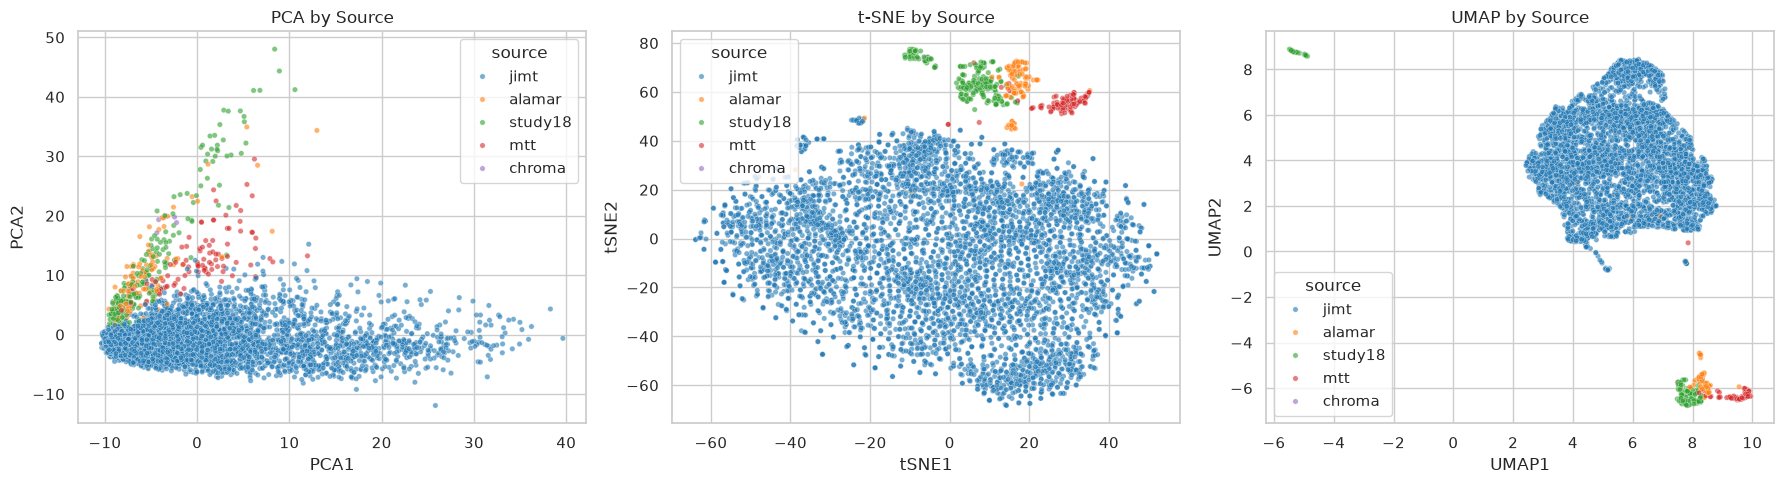

In [28]:
# Plotting Comparison across Labels
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, x_c, y_c) in zip(axes, [('PCA', 'PCA1', 'PCA2'), ('t-SNE', 'tSNE1', 'tSNE2'), ('UMAP', 'UMAP1', 'UMAP2')]):
    sns.scatterplot(data=df_sub, x=x_c, y=y_c, hue='source', alpha=0.6, s=15, ax=ax, palette='tab10')
    ax.set_title(f'{title} by Source')
plt.tight_layout()
plt.show()


=== KNN Performance ===
              precision    recall  f1-score   support

           C       0.92      0.89      0.90      2318
           I       0.90      0.93      0.92      2396
           S       0.48      0.51      0.50        55

    accuracy                           0.91      4769
   macro avg       0.77      0.78      0.77      4769
weighted avg       0.91      0.91      0.91      4769

=== SVM Performance ===
              precision    recall  f1-score   support

           C       0.91      0.92      0.92      2318
           I       0.92      0.93      0.93      2396
           S       0.68      0.24      0.35        55

    accuracy                           0.92      4769
   macro avg       0.84      0.70      0.73      4769
weighted avg       0.92      0.92      0.91      4769



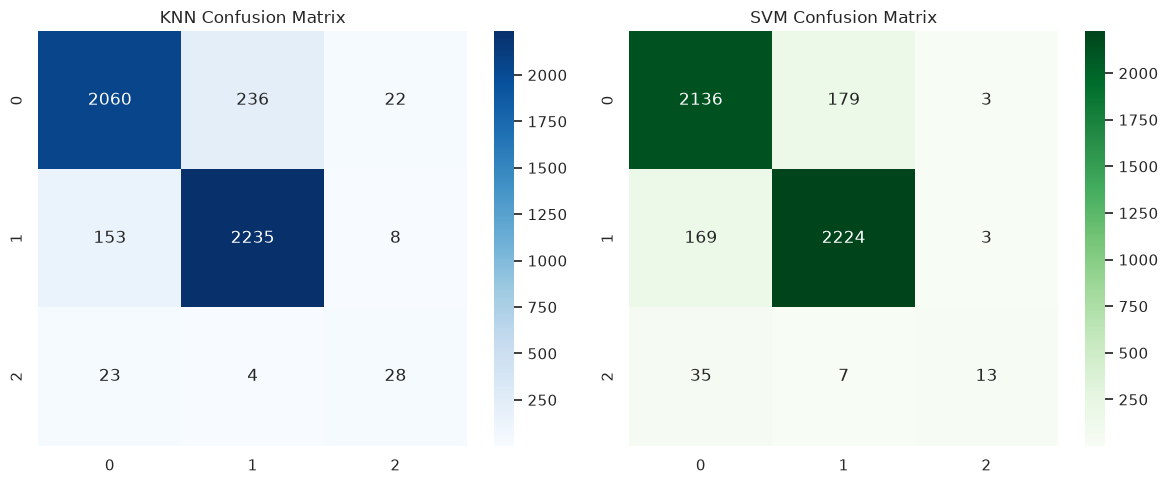

In [20]:
### Supervised Classification with KNN and SVM

y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Scaling without data leakage
train_scaler = StandardScaler()
X_train_scaled = train_scaler.fit_transform(X_train)
X_test_scaled = train_scaler.transform(X_test)

# Model 1: KNN
knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

# Model 2: SVM (RBF Kernel)
svm = SVC(kernel='rbf', C=1.0, random_state=SEED)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

print("=== KNN Performance ===")
print(classification_report(y_test, y_pred_knn))

print("=== SVM Performance ===")
print(classification_report(y_test, y_pred_svm))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('KNN Confusion Matrix')

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('SVM Confusion Matrix')
plt.tight_layout()
plt.show()

/home/nikolaieva/ML/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


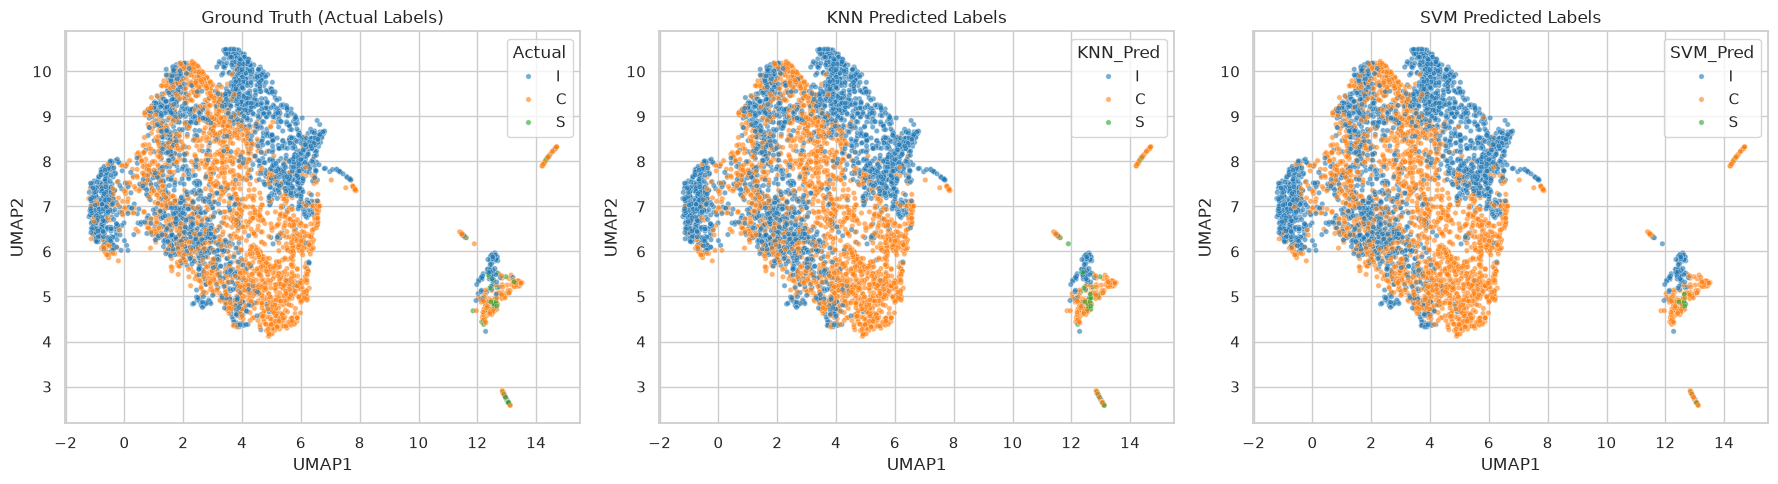

In [30]:
# 1. Fit UMAP on the scaled training features and transform the test set
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
X_test_umap = reducer.fit_transform(X_test_scaled)

# 2. Create a DataFrame for plotting
df_test_viz = pd.DataFrame({
    'UMAP1': X_test_umap[:, 0],
    'UMAP2': X_test_umap[:, 1],
    'Actual': y_test,
    'KNN_Pred': y_pred_knn,
    'SVM_Pred': y_pred_svm
})

# 3. Plot Actual vs KNN vs SVM Predictions side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df_test_viz, x='UMAP1', y='UMAP2', hue='Actual', palette='tab10', s=15, alpha=0.6, ax=axes[0])
axes[0].set_title('Ground Truth (Actual Labels)')

sns.scatterplot(data=df_test_viz, x='UMAP1', y='UMAP2', hue='KNN_Pred', palette='tab10', s=15, alpha=0.6, ax=axes[1])
axes[1].set_title('KNN Predicted Labels')

sns.scatterplot(data=df_test_viz, x='UMAP1', y='UMAP2', hue='SVM_Pred', palette='tab10', s=15, alpha=0.6, ax=axes[2])
axes[2].set_title('SVM Predicted Labels')

plt.tight_layout()
plt.show()

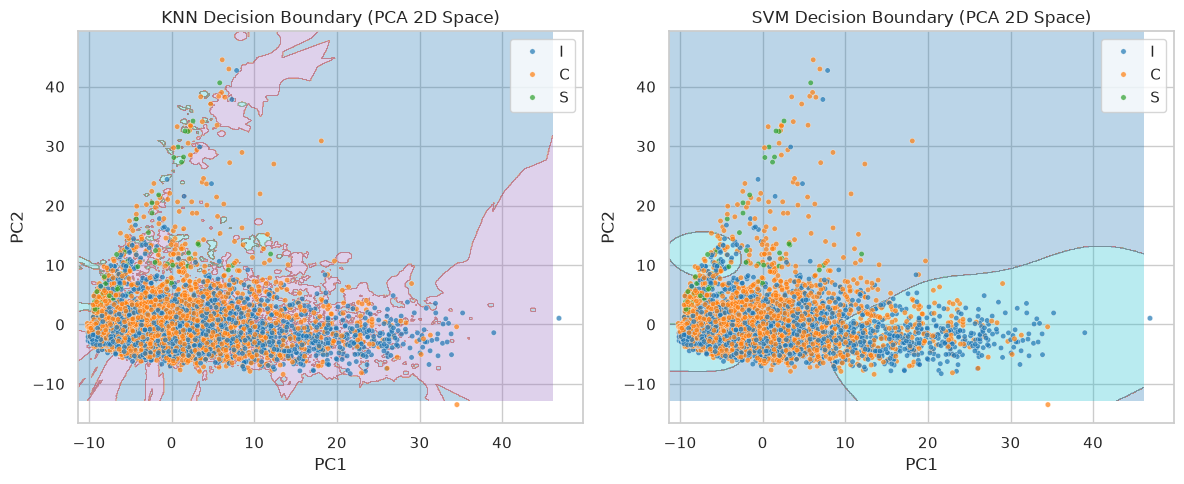

In [29]:
import numpy as np
from sklearn.decomposition import PCA

# 1. Reduce training and testing data to 2 PCA components
pca_2d = PCA(n_components=2, random_state=SEED)
X_train_pca = pca_2d.fit_transform(X_train_scaled)
X_test_pca = pca_2d.transform(X_test_scaled)

# Map string labels to numeric integers for mesh plotting
label_mapping = {l: i for i, l in enumerate(np.unique(y))}
y_train_num = np.array([label_mapping[l] for l in y_train])

# 2. Fit 2D models for boundary visualization
knn_2d = KNeighborsClassifier(n_neighbors=5, weights='distance').fit(X_train_pca, y_train_num)
svm_2d = SVC(kernel='rbf', C=1.0, random_state=SEED).fit(X_train_pca, y_train_num)

# 3. Create grid mesh
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

# 4. Predict mesh grid points
Z_knn = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
Z_svm = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 5. Plot Decision Boundaries
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].contourf(xx, yy, Z_knn, alpha=0.3, cmap='tab10')
sns.scatterplot(x=X_test_pca[:, 0], y=X_test_pca[:, 1], hue=y_test, palette='tab10', s=15, alpha=0.7, ax=axes[0])
axes[0].set_title('KNN Decision Boundary (PCA 2D Space)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].contourf(xx, yy, Z_svm, alpha=0.3, cmap='tab10')
sns.scatterplot(x=X_test_pca[:, 0], y=X_test_pca[:, 1], hue=y_test, palette='tab10', s=15, alpha=0.7, ax=axes[1])
axes[1].set_title('SVM Decision Boundary (PCA 2D Space)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

=== Clustering Evaluation Metrics ===
K-Means      | Silhouette: 0.279 | ARI: 0.015 | NMI: 0.028
Hierarchical | Silhouette: 0.249 | ARI: 0.030 | NMI: 0.057


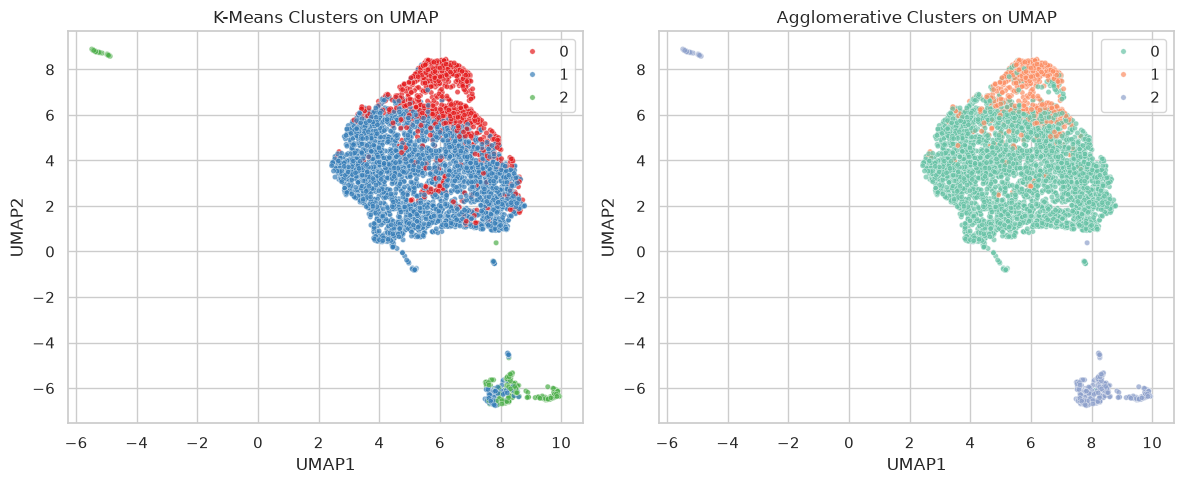

In [21]:
## Unsupervised clustering
n_clusters = len(np.unique(y))

# Method 1: K-Means
kmeans = KMeans(n_clusters=n_clusters, random_state=SEED, n_init=10)
km_labels = kmeans.fit_predict(X_sub_scaled)

# Method 2: Agglomerative Hierarchical Clustering
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
agg_labels = agg.fit_predict(X_sub_scaled)

true_sub_labels = df_sub['label'].values

print("=== Clustering Evaluation Metrics ===")
print(f"K-Means      | Silhouette: {silhouette_score(X_sub_scaled, km_labels):.3f} | ARI: {adjusted_rand_score(true_sub_labels, km_labels):.3f} | NMI: {normalized_mutual_info_score(true_sub_labels, km_labels):.3f}")
print(f"Hierarchical | Silhouette: {silhouette_score(X_sub_scaled, agg_labels):.3f} | ARI: {adjusted_rand_score(true_sub_labels, agg_labels):.3f} | NMI: {normalized_mutual_info_score(true_sub_labels, agg_labels):.3f}")

# Visualizing Clusters on UMAP Space
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(x=df_sub['UMAP1'], y=df_sub['UMAP2'], hue=km_labels, palette='Set1', ax=axes[0], s=15, alpha=0.7)
axes[0].set_title('K-Means Clusters on UMAP')

sns.scatterplot(x=df_sub['UMAP1'], y=df_sub['UMAP2'], hue=agg_labels, palette='Set2', ax=axes[1], s=15, alpha=0.7)
axes[1].set_title('Agglomerative Clusters on UMAP')
plt.tight_layout()
plt.show()


--- Label Breakdown by Source ---
source  alamar  chroma   jimt  mtt  study18    All
label                                             
C          307       4  10464  235      581  11591
I          230       5  11384  136      223  11978
S           16       4      0   58      198    276
All        553      13  21848  429     1002  23845

--- Value Statistics per Label ---
       count        mean        std     min         25%         50%  \
label                                                                 
C      542.0  133.057841  43.289625  90.220  101.555000  117.488889   
I      366.0   23.301403  17.626274   2.454   10.050000   14.750000   
S       74.0   79.910811   5.119226  70.030   74.848889   78.890000   

              75%         max  
label                          
C      151.700000  271.664444  
I       32.045000   69.730000  
S       83.427778   89.970000  


/tmp/ipykernel_2958289/2498686378.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='Value', palette='Set3')


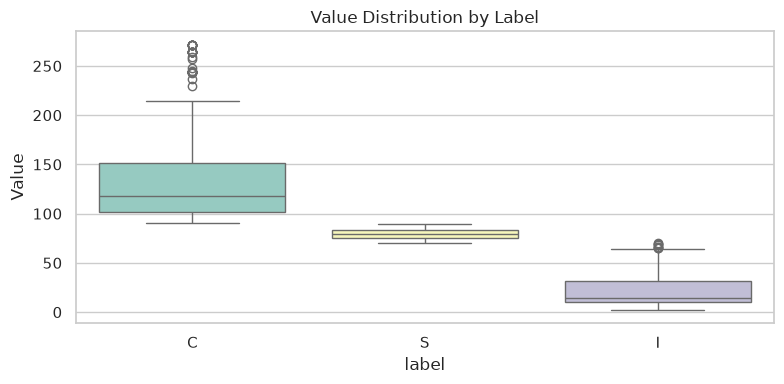

In [22]:
### Label meaning

print("\n--- Label Breakdown by Source ---")
print(pd.crosstab(df['label'], df['source'], margins=True))

print("\n--- Value Statistics per Label ---")
print(df.groupby('label')['Value'].describe())

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='label', y='Value', palette='Set3')
plt.title('Value Distribution by Label')
plt.tight_layout()
plt.show()